# Market share scenarios

Each technology's sub-technology mix: the reference, then every substitution
scenario that re-specifies it. Run by `visualise_market_shares`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

# Snakemake runs this from the repo root, an interactive session from
# notebooks/; neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting  # noqa: E402 — needs the path above
from build_max_reduction import TECHNOLOGY_DIM, respecified_technologies  # noqa: E402
from info_schemas import Intensity, ScenarioType  # noqa: E402

try:
    paths = dict(
        market_share_scenarios=snakemake.input.market_share_scenarios,  # noqa: F821 — injected by the snakemake notebook rule
        figures=snakemake.output.figures,  # noqa: F821
    )
    technology_info = dict(snakemake.params.technology_info)  # noqa: F821
    scenario_info = dict(snakemake.params.scenario_info)  # noqa: F821
    base_scenario = snakemake.params.base_scenario  # noqa: F821
    style = dict(snakemake.params.plotting)  # noqa: F821
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        config = yaml.safe_load(f)
    technology_info = config["technology_info"]
    scenario_info = config["scenarios"]
    base_scenario = config["compare"]["base_scenario"]
    style = config["plotting"]
    paths = dict(
        market_share_scenarios=repo / "data/market_share_scenarios.csv",
        figures=repo / "build/metal_demand/market_shares",
    )

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)
ink = style["ink"]
geometry = style["market_share"]

In [2]:
shares = pd.read_csv(paths["market_share_scenarios"], encoding="utf-8-sig").set_index(
    [Intensity.sub_technology, TECHNOLOGY_DIM]
)
substitution = [
    s for s, info in scenario_info.items()
    if ScenarioType(info["scenario_type"]) is ScenarioType.substitution
]
respecified = respecified_technologies(shares, scenario_info, base_scenario, substitution)

# A technology of one sub-technology has no mix to draw.
blocks = {
    technology: [base_scenario, *[s for s in substitution if technology in respecified[s]]]
    for technology, info in technology_info.items()
    if len(info["sub_technologies"]) > 1
}
palette = geometry["palette"]
names = geometry["names"]
crowded = [t for t in blocks if len(technology_info[t]["sub_technologies"]) > len(palette)]
if crowded:
    raise ValueError(f"more sub-technologies than plotting.market_share.palette has slots: {crowded}")
unnamed = sorted(
    {s for t in blocks for s in technology_info[t]["sub_technologies"]} - set(names)
)
if unnamed:
    raise ValueError(f"plotting.market_share.names has no entry for {unnamed}")

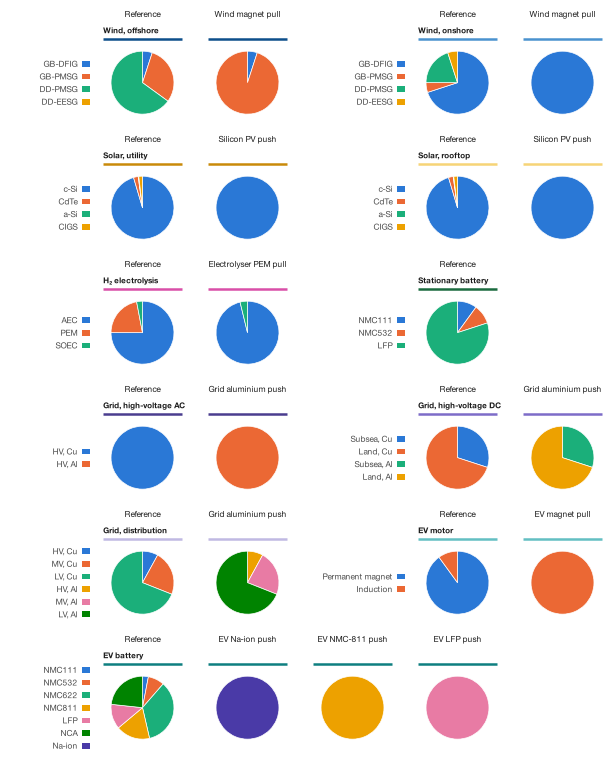

In [3]:
fig, cells = plotting.pie_block_grid(
    {technology: len(scenarios) for technology, scenarios in blocks.items()}, style
)
band = geometry["band"]
title_pad = plotting.band_title_pad(style, "market_share")
outside = []
for technology, scenarios in blocks.items():
    names_ax, pies = cells[technology]
    sub_technologies = technology_info[technology]["sub_technologies"]
    colors = dict(zip(sub_technologies, palette))
    mixes = shares.xs(technology, level=TECHNOLOGY_DIM).reindex(sub_technologies)
    for ax, scenario in zip(pies, scenarios):
        plotting.share_pie(
            ax, mixes[scenario_info[scenario]["market_share_scenario"]], colors, style
        )
        plotting.panel_title(
            ax, style, scenario_info[scenario]["nice_name"], None, extra_pad=title_pad,
            style={"fontsize": geometry["title_size"]}, loc="center",
        )
        outside += plotting.band_rule(ax, ax.figure, technology_info[technology]["color"], band)
    outside.append(
        plotting.band_name(pies[0], technology_info[technology]["nice_name"], ink["primary"], band)
    )
    outside.append(
        plotting.name_column_legend(
            names_ax, plotting.patch_handles(sub_technologies, colors, names), style,
            "market_share",
        )
    )

plotting.save_figure(fig, figures_dir, "market_shares", style, tuple(outside))